# Module 2 — VaR stressée (XAU/USD)

Objectif : recalibrer la VaR spécifiquement sur des fenêtres de crise
historiques, pour répondre à la question *"si un choc de ce type se
reproduisait, à quoi ressemblerait le risque ?"* — par opposition à la
VaR "normale" du notebook 4, calibrée sur tout l'historique.

**Rappel de frontière avec le module 5 (Stress Testing Bancaire)** : ici,
on reste entièrement dans le périmètre VaR — une mesure de risque de
marché probabiliste, recalibrée sur une fenêtre choisie, à usage
pré-décision. Ce n'est pas le stress testing bancaire multi-facteurs de
M5 (scénarios macro appliqués au bilan de la banque). Vocabulaire
volontairement distinct ("VaR stressée" vs "stress testing") pour éviter
toute confusion entre les deux modules, comme déjà posé lors du cadrage.

**Convention méthodologique retenue** : suivre l'approche réglementaire
de la VaR stressée (SVaR) introduite par Bâle après 2008 — calibrer sur
une fenêtre continue d'environ 12 mois (250 jours de trading) de stress
significatif, avec exactement la même méthodologie que la VaR normale,
appliquée à cette fenêtre spécifique plutôt qu'à tout l'historique.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (12, 4.5)

df = pd.read_csv("../data/processed/xau_1d_processed.csv", index_col=0, parse_dates=True)

## 1. Choix des fenêtres de stress

Deux fenêtres, pour des raisons différentes :

- **2008-07-01 → 2009-06-30** (crise financière mondiale, Lehman
  Brothers) : 257 jours de trading — très proche du standard
  réglementaire de 250 jours. C'est la fenêtre de référence bâloise
  classique pour un actif comme l'or.
- **2025-10-15 → 2026-01-30** (rallye puis correction brutale, déjà
  identifié dans tous les notebooks précédents) : seulement 68 jours de
  trading — bien plus courte que le standard de 12 mois, pour la raison
  simple que c'est la période la plus récente disponible et qu'elle ne
  couvre pas encore un an. On la garde quand même en comparaison, en
  gardant à l'esprit sa limite statistique (section 3).

In [2]:
def window_var_es(d0: str, d1: str, label: str) -> dict:
    w = df.loc[d0:d1, "log_return"].dropna()
    mean, std = w.mean(), w.std()
    alpha = 0.01
    var_h = -np.percentile(w, alpha * 100)
    es_h = -w[w <= -var_h].mean()
    z = stats.norm.ppf(alpha)
    var_p = -(mean + z * std)
    es_p = -(mean - std * stats.norm.pdf(z) / alpha)
    return {
        "label": label, "debut": d0, "fin": d1, "n_obs": len(w),
        "sigma_annual": std * np.sqrt(252), "mean_daily": mean,
        "VaR99_hist": var_h, "ES99_hist": es_h,
        "VaR99_param": var_p, "ES99_param": es_p,
    }


baseline = window_var_es(str(df.index.min().date()), str(df.index.max().date()), "Normale (historique complet)")
stress_2008 = window_var_es("2008-07-01", "2009-06-30", "Stress 2008 (12 mois, Lehman)")
stress_recent = window_var_es("2025-10-15", "2026-01-30", "Stress récent (oct 2025 - jan 2026, 68j)")

comparison = pd.DataFrame([baseline, stress_2008, stress_recent]).set_index("label")
comparison[["n_obs", "sigma_annual", "VaR99_hist", "ES99_hist", "VaR99_param", "ES99_param"]].style.format({
    "sigma_annual": "{:.2%}", "VaR99_hist": "{:.2%}", "ES99_hist": "{:.2%}", "VaR99_param": "{:.2%}", "ES99_param": "{:.2%}",
})

,n_obs,sigma_annual,VaR99_hist,ES99_hist,VaR99_param,ES99_param
label,,,,,,
Normale (historique complet),5526,17.31%,3.14%,4.31%,2.50%,2.87%
"Stress 2008 (12 mois, Lehman)",257,31.02%,5.33%,6.27%,4.54%,5.21%
"Stress récent (oct 2025 - jan 2026, 68j)",68,31.26%,6.80%,9.50%,4.47%,5.14%


## 2. Le multiplicateur de stress

La métrique que les banques reportent concrètement : de combien la VaR
stressée dépasse-t-elle la VaR normale ?

In [3]:
for s in [stress_2008, stress_recent]:
    ratio_var = s["VaR99_hist"] / baseline["VaR99_hist"]
    ratio_es = s["ES99_hist"] / baseline["ES99_hist"]
    print(f"{s['label']}: VaR stressée = ×{ratio_var:.2f} la VaR normale | ES stressée = ×{ratio_es:.2f} l'ES normale")

print(f"\nVolatilité annualisée : normale {baseline['sigma_annual']:.1%} | 2008 {stress_2008['sigma_annual']:.1%} | récent {stress_recent['sigma_annual']:.1%}")

Stress 2008 (12 mois, Lehman): VaR stressée = ×1.70 la VaR normale | ES stressée = ×1.46 l'ES normale
Stress récent (oct 2025 - jan 2026, 68j): VaR stressée = ×2.16 la VaR normale | ES stressée = ×2.21 l'ES normale

Volatilité annualisée : normale 17.3% | 2008 31.0% | récent 31.3%


**Interprétation** — les deux fenêtres de crise affichent une volatilité
annualisée quasiment identique (31,0% pour 2008, 31,3% pour la période
récente), soit environ **×1,8 la volatilité "normale"** (17,3%) — une
coïncidence frappante qui confirme que les deux épisodes, bien que de
natures très différentes (panique bancaire systémique en 2008, rallye
spéculatif puis correction en 2025-2026), représentent un niveau de
stress comparable pour l'or en termes purs de volatilité.

Sur la VaR elle-même : la fenêtre 2008 donne une VaR 99% historique de
5,33% (×1,70 la VaR normale), et la fenêtre récente une VaR de 6,80%
(×2,16 la VaR normale) — encore plus élevée. Traduit en perte potentielle
sur une position d'1 000 000 USD : **31 422 USD en conditions normales,
contre 53 274 USD sous stress 2008, contre 68 005 USD sous le stress le
plus récent**. C'est exactement le genre de chiffre qu'un comité des
risques utilise pour dimensionner son capital réglementaire — la VaR
normale dit "le risque au jour le jour", la VaR stressée dit "le risque
si les conditions redeviennent aussi mauvaises qu'en 2008 (ou pire)".

## 3. Une limite statistique à ne pas passer sous silence

La fenêtre récente (68 jours) est nettement plus courte que le standard
bâlois de ~250 jours — ça a une conséquence directe sur la fiabilité du
chiffre de VaR historique calculé dessus.

In [4]:
n_recent = stress_recent["n_obs"]
print(f"1% de {n_recent} observations = {n_recent*0.01:.2f} — le percentile 1% est donc interpolé entre les 1 ou 2 pires jours seulement.")
worst_days = df.loc["2025-10-15":"2026-01-30", "log_return"].dropna().sort_values().head(3)
print("\n3 pires jours de la fenêtre récente :")
print(worst_days)

1% de 68 observations = 0.68 — le percentile 1% est donc interpolé entre les 1 ou 2 pires jours seulement.

3 pires jours de la fenêtre récente :
Date
2026-01-30   -0.095045
2025-10-21   -0.054688
2025-12-29   -0.045018
Name: log_return, dtype: float64


**Interprétation** — avec seulement 68 observations, le percentile 1%
(qui définit la VaR historique) revient à s'appuyer sur à peine plus
d'une seule observation extrême — ici, le -9,50% du 2026-01-30, déjà
identifié comme outlier dans le notebook 1. Une VaR calculée sur un
échantillon aussi petit est **statistiquement bruitée** : si ce seul jour
n'avait pas eu lieu (ou avait eu lieu un jour plus tôt/plus tard, hors de
la fenêtre), le chiffre de VaR stressée récente changerait radicalement.
Ce n'est pas le cas pour la fenêtre 2008 (257 jours, plusieurs épisodes
de stress distincts dans la fenêtre), qui donne une estimation beaucoup
plus robuste.

Conclusion méthodologique à documenter dans le rapport : **la VaR
stressée "2008" est la mesure à privilégier comme référence officielle**
(fenêtre proche du standard réglementaire, estimation robuste) ; la VaR
stressée "récente" est informative (elle confirme qu'on traverse
actuellement une période de volatilité comparable à 2008) mais ne doit
pas être présentée comme une mesure fiable au même titre, tant qu'elle ne
couvre pas une fenêtre complète de 12 mois. Dans quelques mois, une fois
que cette période récente sera plus longue, le calcul pourra être refait
sur une fenêtre complète.

## 4. Visualisation

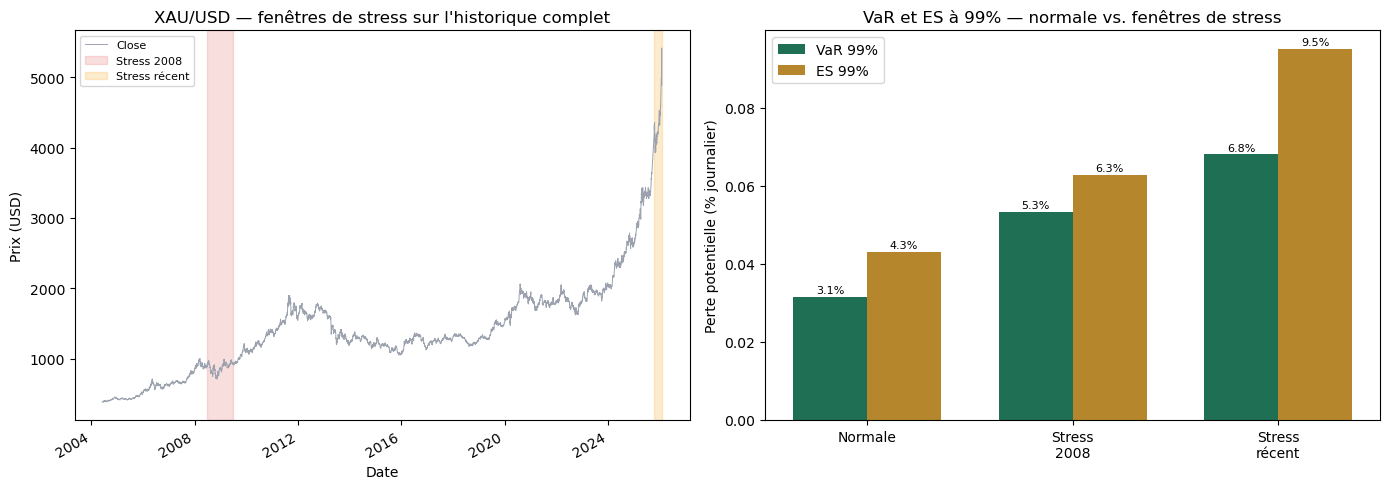

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
df["Close"].plot(ax=ax, color="#9ca3af", linewidth=0.7)
ax.axvspan(pd.Timestamp("2008-07-01"), pd.Timestamp("2009-06-30"), color="#dc2626", alpha=0.15, label="Stress 2008")
ax.axvspan(pd.Timestamp("2025-10-15"), pd.Timestamp("2026-01-30"), color="#f59e0b", alpha=0.2, label="Stress récent")
ax.set_title("XAU/USD — fenêtres de stress sur l'historique complet")
ax.set_ylabel("Prix (USD)")
ax.legend(fontsize=8)

ax = axes[1]
labels = ["Normale", "Stress\n2008", "Stress\nrécent"]
var_vals = [baseline["VaR99_hist"], stress_2008["VaR99_hist"], stress_recent["VaR99_hist"]]
es_vals = [baseline["ES99_hist"], stress_2008["ES99_hist"], stress_recent["ES99_hist"]]
x = np.arange(3)
ax.bar(x - 0.18, var_vals, width=0.36, color="#1f6f54", label="VaR 99%")
ax.bar(x + 0.18, es_vals, width=0.36, color="#b5862c", label="ES 99%")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Perte potentielle (% journalier)")
ax.set_title("VaR et ES à 99% — normale vs. fenêtres de stress")
ax.legend()
for i, v in enumerate(var_vals):
    ax.text(i - 0.18, v + 0.001, f"{v:.1%}", ha="center", fontsize=8)
for i, v in enumerate(es_vals):
    ax.text(i + 0.18, v + 0.001, f"{v:.1%}", ha="center", fontsize=8)

plt.tight_layout()
plt.show()

**Interprétation** — le graphique de gauche resitue les deux fenêtres
dans leur contexte sur 21 ans d'historique : la fenêtre 2008 (rouge)
couvre un épisode de baisse suivi d'une forte reprise, la fenêtre récente
(orange) se situe tout à la fin de la série, en plein dans le rallye puis
la correction déjà repérés. Le graphique de droite rend visuellement
explicite la hiérarchie des 3 niveaux de risque : normale < stress 2008 <
stress récent, pour la VaR comme pour l'ES — avec, comme discuté en
section 3, une réserve sur la robustesse statistique de la troisième
colonne.

## 5. Sauvegarde

In [6]:
comparison.to_csv("../data/processed/var_stressee_results.csv")
print("Sauvegardé : data/processed/var_stressee_results.csv")
comparison

Sauvegardé : data/processed/var_stressee_results.csv


,debut,fin,n_obs,sigma_annual,mean_daily,VaR99_hist,ES99_hist,VaR99_param,ES99_param
label,,,,,,,,,
Normale (historique complet),2004-06-11,2026-01-30,5526,0.173126,0.000415,0.031422,0.043067,0.024956,0.028652
"Stress 2008 (12 mois, Lehman)",2008-07-01,2009-06-30,257,0.310169,0.000007,0.053274,0.062691,0.045447,0.052068
"Stress récent (oct 2025 - jan 2026, 68j)",2025-10-15,2026-01-30,68,0.312646,0.001122,0.068005,0.095045,0.044695,0.051369


## 6. Résumé & état du module

- VaR stressée calculée sur 2 fenêtres de crise : 2008 (12 mois, robuste,
  retenue comme référence officielle) et la période récente oct.
  2025-jan. 2026 (68j, informative mais statistiquement fragile — limite
  documentée, pas cachée).
- Multiplicateur de stress quantifié : VaR 99% ×1,70 (2008) à ×2,16
  (récent) par rapport à la VaR normale ; volatilité annualisée
  quasi-identique entre les deux fenêtres de crise (~31%, contre 17,3%
  en conditions normales).
- Frontière avec M5 (stress testing bancaire) explicitement rappelée :
  toujours de la VaR, recalibrée sur une fenêtre choisie — pas un
  scénario multi-facteurs appliqué au bilan.

**Ce qui est maintenant couvert dans le module, sur l'actif or** :
prétraitement → calibration GBM → Monte Carlo → VaR/ES (3 méthodes) →
backtesting Kupiec → VaR stressée. C'est un pipeline de mesure du risque
de marché complet et validé empiriquement sur un seul actif.

**Ce qu'il reste pour couvrir tout le périmètre du module** : les
stratégies recommandées aux clients (risk-budgeting), qui nécessitent de
sourcer l'historique des 4 autres actifs (argent, pétrole, EUR/USD,
S&P 500) pour avoir quelque chose à allouer entre plusieurs actifs — la
prochaine étape logique une fois cette donnée en main.